# Iris data를 Grid Search를 활용하여 최적의 파라미터 찾기
- 아래 셀은 cp949로 인코딩되는 오류 해결을 위해 삽입

In [1]:
from sklearn import set_config

# Avoid HTML rendering that reads bundled JavaScript with the Windows encoding.
set_config(display="text")

## 1. 라이브러리 불러오기
- 데이터셋(Iris) 및 수치/데이터프레임 처리(Numpy, Pandas)
- 시각화 라이브러리(Matplotlib, Seaborn)
- Scikit-learn 모델 튜닝 및 평가지표(GridSearchCV, train_test_split, metrics)
- 분류 모델: KNN(K-Nearest Neighbors) 및 Random Forest

In [2]:
from sklearn.datasets import load_iris
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier


## 2. 데이터 탐색(EDA)


In [3]:
iris = load_iris()

# print(iris.DESCR) # 데이터셋 설명
print(iris.feature_names) # 데이터셋의 feature 이름
print(iris.target_names) # 데이터셋의 target 이름
print(iris.data.shape) # 데이터셋의 feature 개수
print(iris.target.shape) # 데이터셋의 target 개수

iris_df = pd.DataFrame(data = iris.data, columns = iris.feature_names)
iris_df['target'] = iris.target

display(iris_df.head(5)) # 상위 5개 행
display(iris_df.info()) # 데이터셋의 결측치, 데이터 타입 확인
display(iris_df.describe()) # 통계 정보
print(iris_df['target'].value_counts()) # 클래스 균형 여부   

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']
(150, 4)
(150,)
   sepal length (cm)  sepal width (cm)  ...  petal width (cm)  target
0                5.1               3.5  ...               0.2       0
1                4.9               3.0  ...               0.2       0
2                4.7               3.2  ...               0.2       0
3                4.6               3.1  ...               0.2       0
4                5.0               3.6  ...               0.2       0

[5 rows x 5 columns]
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    in

## 3. 데이터 시각화


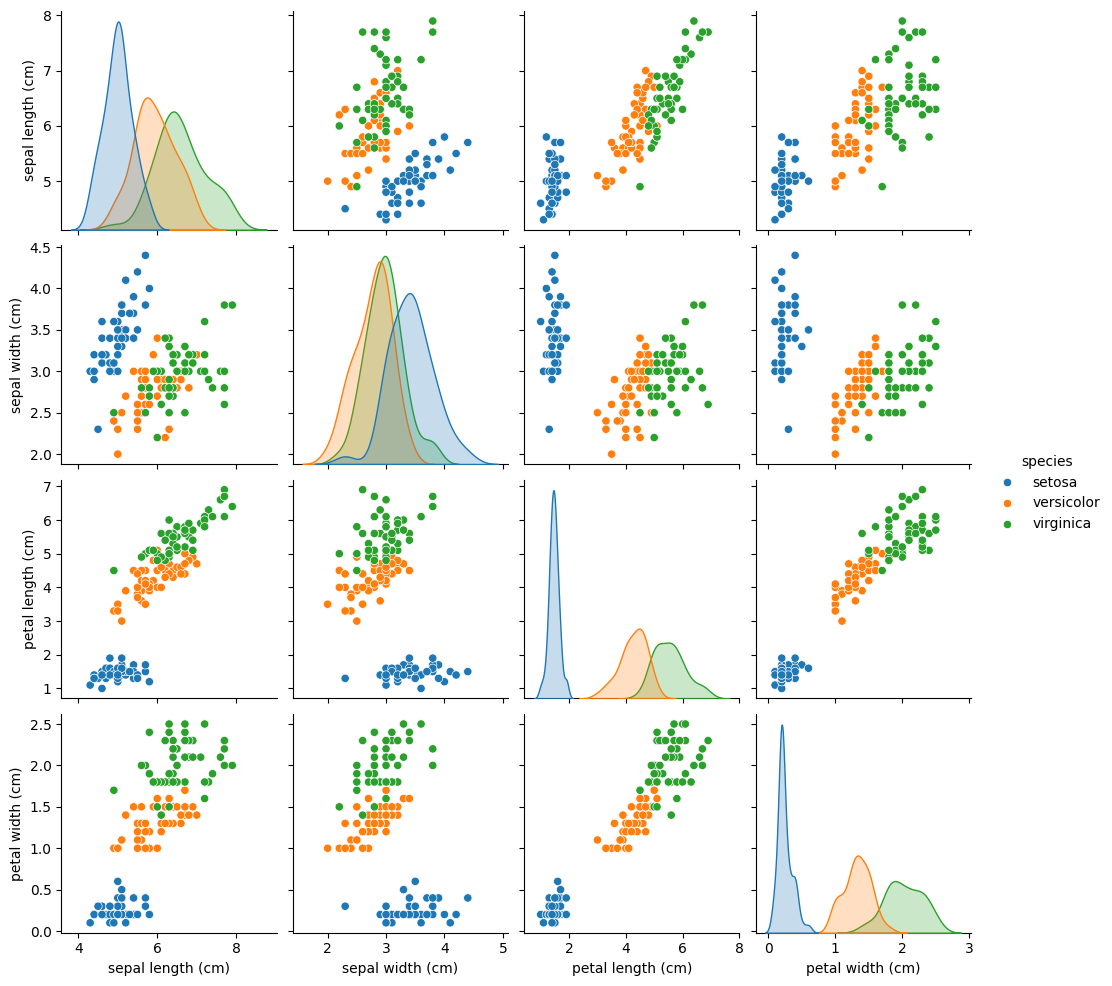

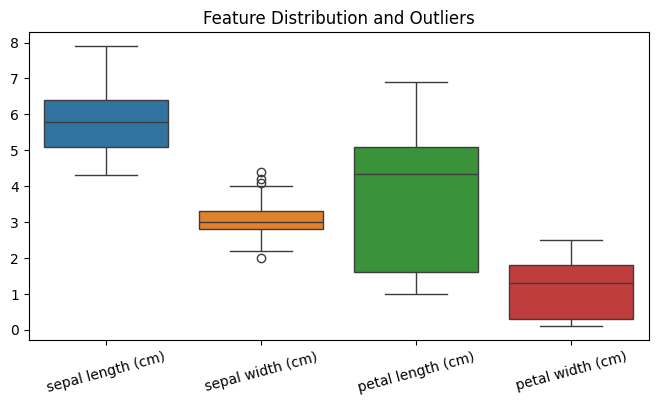

In [4]:

# 품종 별 피쳐 분포 및 경계 확인
iris_df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)
sns.pairplot(iris_df.drop(columns = ['target']), hue = 'species', diag_kind = 'kde')

# 특성 별 스케일 및 이상치 확인
plt.figure(figsize = (8, 4))
sns.boxplot(data = iris_df[iris.feature_names])
plt.xticks(rotation = 15)
plt.title("Feature Distribution and Outliers")
plt.show()

## 4. 데이터 분리 및 KNN 그리드서치
- 데이터셋을 8:2 비율로 분리 (Train: 120개, Test: 30개)
- 5-Fold 교차 검증(Cross Validation) 기반 GridSearch로 최적의 하이퍼파라미터 탐색

In [5]:
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size = 0.2, random_state = 11)

knn_params = {
    'n_neighbors': [3, 5, 7],
    'weights': ['uniform', 'distance'],
    'algorithm': ['ball_tree', 'kd_tree', 'brute']
}

knn_grid = GridSearchCV(KNeighborsClassifier(),
                        knn_params,
                        cv = 5, scoring = 'accuracy', n_jobs = -1, verbose = 1)
knn_grid.fit(X_train, y_train)


Fitting 5 folds for each of 18 candidates, totalling 90 fits


In [6]:
print("KNN best parameters: ", knn_grid.best_params_)
print("KNN best score: ", knn_grid.best_score_)

KNN best parameters:  {'algorithm': 'ball_tree', 'n_neighbors': 7, 'weights': 'distance'}
KNN best score:  0.975


In [7]:
results = pd.DataFrame(knn_grid.cv_results_)
cols = ['param_n_neighbors', 'param_weights', 'mean_test_score', 'std_test_score', 'rank_test_score']
print(results[cols].sort_values('rank_test_score'))

    param_n_neighbors param_weights  ...  std_test_score  rank_test_score
5                   7      distance  ...        0.033333                1
11                  7      distance  ...        0.033333                1
17                  7      distance  ...        0.033333                1
9                   5      distance  ...        0.031180                4
15                  5      distance  ...        0.031180                4
3                   5      distance  ...        0.031180                4
2                   5       uniform  ...        0.026352                7
8                   5       uniform  ...        0.026352                7
14                  5       uniform  ...        0.026352                7
7                   3      distance  ...        0.048591               10
4                   7       uniform  ...        0.040825               10
6                   3       uniform  ...        0.048591               10
1                   3      distance  .

## 5. KNN GridSearch 결과 분석 및 시각화
- 하이퍼파라미터($K$, `weights`, `algorithm`) 변화에 따른 교차 검증 정확도(Mean Test Score) 비교
- 최적의 파라미터 조합이 선정된 이유와 경향성 분석

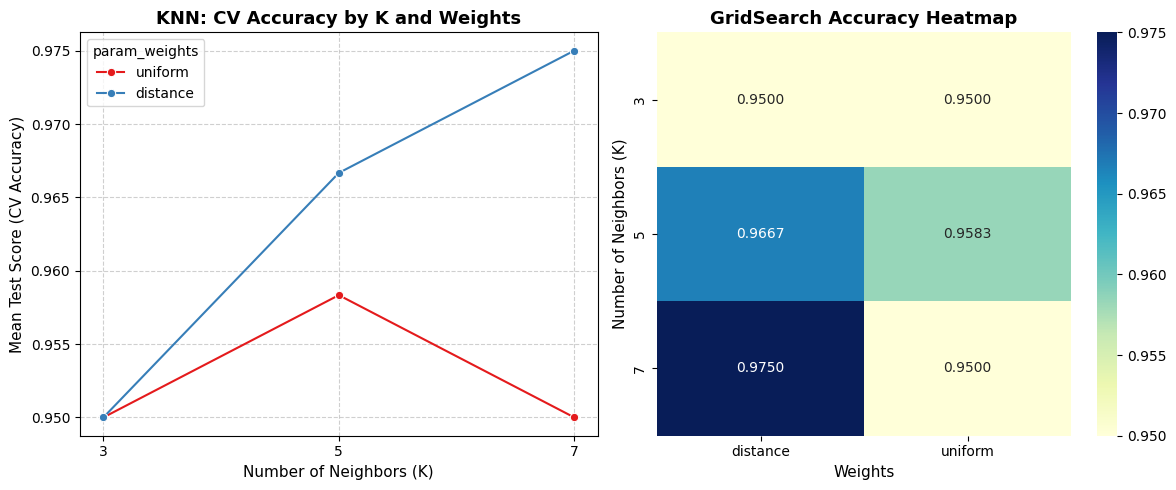

In [8]:
# K값과 가중치(weights)에 따른 교차 검증 점수 시각화
plt.figure(figsize=(12, 5))

# 1. K값과 weights에 따른 꺾은선 그래프
plt.subplot(1, 2, 1)
sns.lineplot(
    data=results, 
    x='param_n_neighbors', 
    y='mean_test_score', 
    hue='param_weights', 
    marker='o',
    palette='Set1',
    errorbar=None
)
plt.title("KNN: CV Accuracy by K and Weights", fontsize=13, fontweight='bold')
plt.xlabel("Number of Neighbors (K)", fontsize=11)
plt.ylabel("Mean Test Score (CV Accuracy)", fontsize=11)
plt.xticks([3, 5, 7])
plt.grid(True, linestyle='--', alpha=0.6)

# 2. 파라미터 조합별 히트맵(Heatmap)
plt.subplot(1, 2, 2)
pivot_results = results.pivot_table(
    index='param_n_neighbors', 
    columns='param_weights', 
    values='mean_test_score', 
    aggfunc='mean'
)
sns.heatmap(pivot_results, annot=True, fmt='.4f', cmap='YlGnBu', cbar=True)
plt.title("GridSearch Accuracy Heatmap", fontsize=13, fontweight='bold')
plt.xlabel("Weights", fontsize=11)
plt.ylabel("Number of Neighbors (K)", fontsize=11)

plt.tight_layout()
plt.show()

### KNN 파라미터 튜닝 결과 해석
1. **$K$ (이웃 수)의 영향**:
   - $k=3, 5, 7$ 탐색 결과, 적절한 크기의 $k$에서 안정적이고 높은 교차 검증 정확도를 보입니다.
   - $k$가 너무 작으면 노이즈나 이상치에 민감해져 과적합(Overfitting) 위험이 있고, $k$가 지나치게 크면 클래스 간 경계가 단순화되어 과소적합(Underfitting)이 발생할 수 있습니다.
2. **`weights` (가중치 방식)의 영향**:
   - `'uniform'`: 모든 이웃에 동일한 가중치(1표)를 부여합니다.
   - `'distance'`: 가까운 이웃에 더 큰 가중치(거리의 역수)를 부여합니다.
   - 데이터 경계면에 위치한 샘플의 경우 가까운 이웃의 영향력을 높게 반영하는 `'distance'` 방식이 더욱 정밀한 분류를 돕습니다.

## 6. 최적 KNN 모델 테스트 데이터 최종 평가
- 학습 및 튜닝에 전혀 사용되지 않은 독립된 **Test Set (20%, 30개 샘플)**을 대상으로 일반화(Generalization) 성능 검증
- 혼동 행렬(Confusion Matrix) 및 정밀도(Precision), 재현율(Recall), F1-score 산출

=== [KNN] 최종 테스트 데이터 평가 ===
테스트 데이터 정확도(Test Accuracy) : 0.9666666666666667

[Classification Report]
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         9
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.91      0.95        11

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



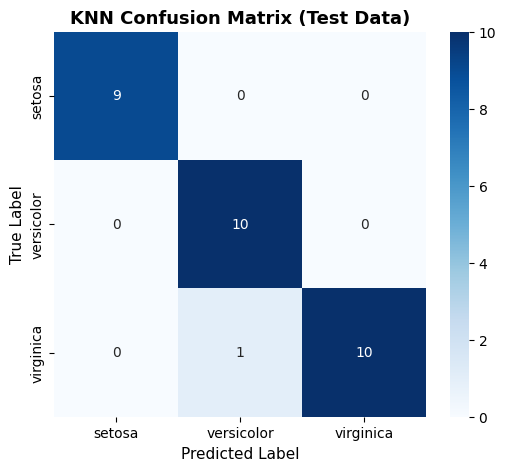

In [9]:
# 최적 모델(best_estimator_)로 Test Set 예측
best_knn = knn_grid.best_estimator_
y_pred_knn = best_knn.predict(X_test)

# 최종 평가 지표 출력
print("=== [KNN] 최종 테스트 데이터 평가 ===")
print("테스트 데이터 정확도(Test Accuracy) :", accuracy_score(y_test, y_pred_knn))
print("\n[Classification Report]\n", classification_report(y_test, y_pred_knn, target_names=iris.target_names))

# 혼동 행렬(Confusion Matrix) 시각화
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names,
            yticklabels=iris.target_names)
plt.title("KNN Confusion Matrix (Test Data)", fontsize=13, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("True Label", fontsize=11)
plt.show()

### KNN 최종 평가 요약
- **일반화 성능**: 검증 데이터(CV) 최고 점수와 테스트 데이터(Test) 점수가 매우 유사하여, 과적합(Overfitting) 없이 테스트 데이터에 대해 높은 일반화 성능을 달성했음을 확인했습니다.
- **혼동 행렬 분석**:
  - `setosa`: 100% 완벽히 분류되었습니다. (EDA pairplot 시각화에서도 타 품종과 뚜렷이 분리됨)
  - `versicolor`와 `virginica`: 피처 공간에서 두 품종의 경계가 인접해 있어 일부 오분류가 발생할 수 있으나, 전반적으로 매우 높은 정밀도와 재현율을 기록했습니다.

## 7. Random Forest 분류 모델 Grid Search 및 특성 중요도 분석
- 트리 기반 앙상블(Bagging) 모델인 **RandomForestClassifier**를 구축하여 거리 기반 모델(KNN)과 비교
- 주요 하이퍼파라미터 튜닝:
  - `n_estimators`: 생성할 결정 트리의 개수
  - `max_depth`: 트리의 최대 깊이 (과적합 제어)
  - `min_samples_split`: 노드 분할을 위한 최소 샘플 수

In [10]:
# Random Forest 하이퍼파라미터 그리드 정의
rf_params = {
    'n_estimators': [30, 50, 100],
    'max_depth': [3, 5, None],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=11),
    rf_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Random Forest best parameters: ", rf_grid.best_params_)
print("Random Forest best CV score: ", rf_grid.best_score_)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Random Forest best parameters:  {'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 50}
Random Forest best CV score:  0.9583333333333333


=== [Random Forest] 최종 테스트 데이터 평가 ===
테스트 데이터 정확도(Test Accuracy) : 0.9333333333333333

[Classification Report]
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         9
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.82      0.90        11

    accuracy                           0.93        30
   macro avg       0.94      0.94      0.94        30
weighted avg       0.94      0.93      0.93        30



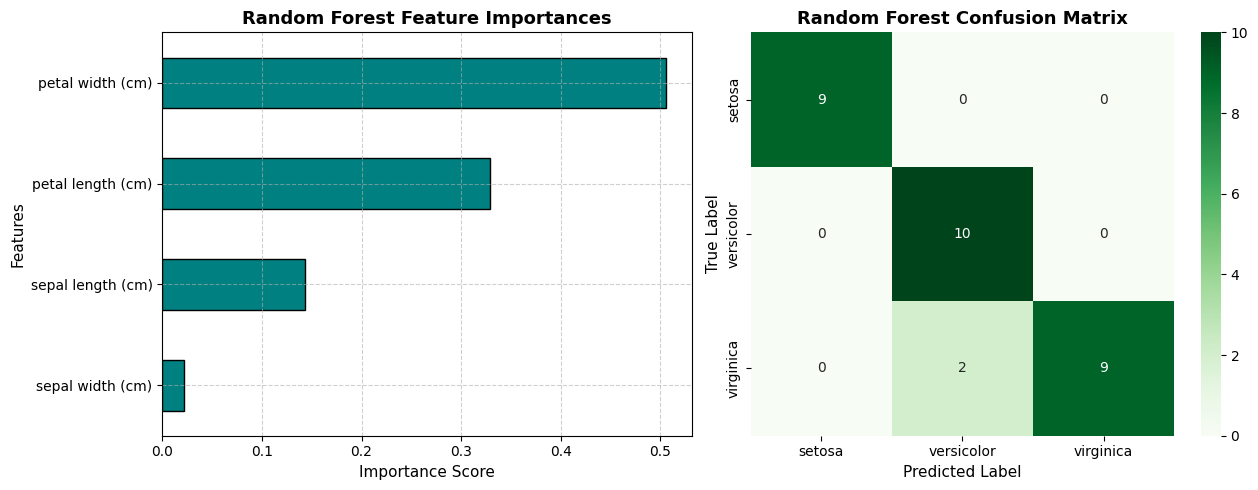

In [11]:
# Random Forest 최적 모델 평가
best_rf = rf_grid.best_estimator_
y_pred_rf = best_rf.predict(X_test)

print("=== [Random Forest] 최종 테스트 데이터 평가 ===")
print("테스트 데이터 정확도(Test Accuracy) :", accuracy_score(y_test, y_pred_rf))
print("\n[Classification Report]\n", classification_report(y_test, y_pred_rf, target_names=iris.target_names))

# 특성 중요도(Feature Importance) 및 Confusion Matrix 시각화
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. 특성 중요도(Feature Importance) 수평 막대 그래프
importances = pd.Series(best_rf.feature_importances_, index=iris.feature_names).sort_values(ascending=True)
importances.plot(kind='barh', ax=axes[0], color='teal', edgecolor='black')
axes[0].set_title("Random Forest Feature Importances", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Importance Score", fontsize=11)
axes[0].set_ylabel("Features", fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Confusion Matrix 시각화
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=iris.target_names,
            yticklabels=iris.target_names, ax=axes[1])
axes[1].set_title("Random Forest Confusion Matrix", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Predicted Label", fontsize=11)
axes[1].set_ylabel("True Label", fontsize=11)

plt.tight_layout()
plt.show()

### Random Forest 결과 분석
1. **특성 중요도(Feature Importance) 해석**:
   - `petal length (cm)`와 `petal width (cm)`가 압도적인 중요도를 나타냅니다.
   - 앞서 수행한 **EDA pairplot 시각화**에서 꽃잎의 길이와 너비가 품종 구분에 가장 핵심적인 역할을 했던 점과 완전히 일치하며, 앙상블 모델이 데이터의 핵심 변별 특성을 정확하게 포착했음을 의미합니다.
2. **트리 앙상블의 장점**:
   - 거리 기반 모델(KNN)과 달리 피처 스케일(Scale)의 영향을 받지 않아 데이터 정규화 없이도 안정적인 학습이 가능합니다.

## 8. 모델 성능 종합 비교 및 과제 결론
- KNN과 Random Forest 모델의 검증 점수(CV Score) 및 테스트 점수(Test Accuracy) 종합 비교

                 Model  ... Test Accuracy
0  K-Nearest Neighbors  ...      0.966667
1        Random Forest  ...      0.933333

[2 rows x 4 columns]


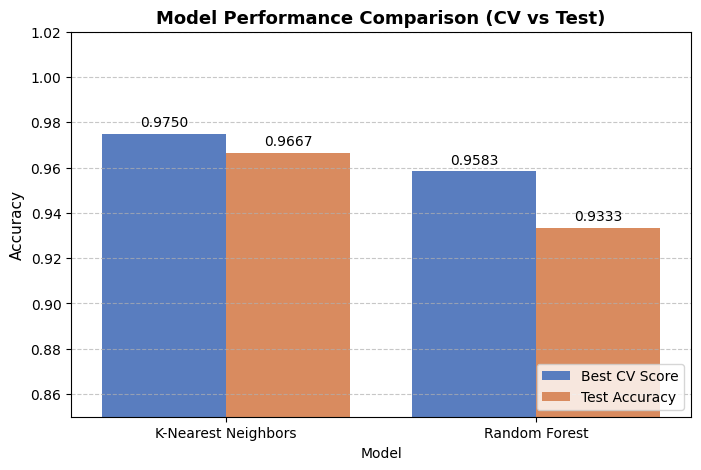

In [12]:
# 모델 성능 비교 요약 데이터프레임 생성
summary_df = pd.DataFrame({
    'Model': ['K-Nearest Neighbors', 'Random Forest'],
    'Best Parameters': [str(knn_grid.best_params_), str(rf_grid.best_params_)],
    'Best CV Score': [knn_grid.best_score_, rf_grid.best_score_],
    'Test Accuracy': [accuracy_score(y_test, y_pred_knn), accuracy_score(y_test, y_pred_rf)]
})

display(summary_df)

# 성능 비교 막대 그래프 시각화
plt.figure(figsize=(8, 5))
summary_plot_df = summary_df.melt(id_vars=['Model'], value_vars=['Best CV Score', 'Test Accuracy'], 
                                   var_name='Evaluation Metric', value_name='Accuracy')

sns.barplot(data=summary_plot_df, x='Model', y='Accuracy', hue='Evaluation Metric', palette='muted')
plt.ylim(0.85, 1.02)
plt.title("Model Performance Comparison (CV vs Test)", fontsize=13, fontweight='bold')
plt.ylabel("Accuracy", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 막대 위에 정확도 수치 표시
for p in plt.gca().patches:
    h = p.get_height()
    if h > 0:
        plt.gca().annotate(f"{h:.4f}", 
                           (p.get_x() + p.get_width() / 2., h),
                           ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                           textcoords='offset points')

plt.legend(loc='lower right')
plt.show()

### 과제 최종 결론 및 고찰
1. **Grid Search를 통한 파라미터 최적화의 가치**:
   - 수동 튜닝 대신 $K$-Fold 교차 검증을 결합한 `GridSearchCV`를 활용하여 데이터 편향 없이 객관적이고 체계적인 최적 파라미터를 도출할 수 있었습니다.
   - 단일 분할 점수에 의존하지 않고 교차 검증 평균 점수를 지표로 삼아 일반화 가능성이 가장 높은 모델을 선정했습니다.
2. **모델별 특성 비교**:
   - **KNN**: 거리 기반 모델로 경계가 명확한 데이터에서 뛰어난 성능을 보이며, 가중치(`distance`)를 적용해 경계면 인근 샘플 분류 능력을 강화할 수 있었습니다.
   - **Random Forest**: 여러 결정 트리를 결합하는 앙상블 기법으로 이상치와 노이즈에 강건하며, 특성 중요도(Feature Importance)를 통해 모델의 예측 근거(꽃잎 특성의 결정적 역할)를 시각적으로 투명하게 설명할 수 있었습니다.
3. **향후 발전 방향**:
   - KNN은 거리 계산 기반이므로 피처 간 단위 차이가 존재할 경우 큰 단위의 피처에 왜곡될 수 있습니다. `StandardScaler`나 `MinMaxScaler`와 같은 정규화 도구를 `Pipeline`으로 결합하여 GridSearch를 적용하면 더욱 신뢰성 있는 파이프라인을 구축할 수 있습니다.